<h1><center>Metrics (accuracy, precision, recall, F1-score)

In [87]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [88]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn .metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve,roc_auc_score, log_loss


In [89]:
# création des données
X, y = make_classification(
    n_samples=1000, n_features=5, n_classes=2,
    weights=[0.7, 0.3], random_state=42
)

In [90]:
# Séparation des données en train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.3, random_state= 42)


In [91]:
# Entrainement du modèle
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [92]:
# prédictions
y_pred = model.predict(X_test) # classe 0 ou 1
y_pred_proba = model.predict_proba(X_test)[:, 1]  # probas pour la classe 1


In [93]:
y_pred_proba = model.predict_proba(X_test)[:, 1]  # probas pour la classe 1

In [94]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)


auc = roc_auc_score(y_test, y_pred_proba)
logloss = log_loss(y_test, y_pred_proba)


In [95]:
print("Accuracy :", round(acc, 3)* 100,"%")
print("Precision :", round(prec, 3)* 100,"%")
print("Recall :", round(rec, 3)* 100,"%")
print("F1-score :", round(f1, 3)* 100,"%")

print("\n")
print("AUC :", round(auc, 3))
print("Log Loss :", round(logloss, 3))

Accuracy : 89.3 %
Precision : 88.5 %
Recall : 77.8 %
F1-score : 82.8 %


AUC : 0.957
Log Loss : 0.259


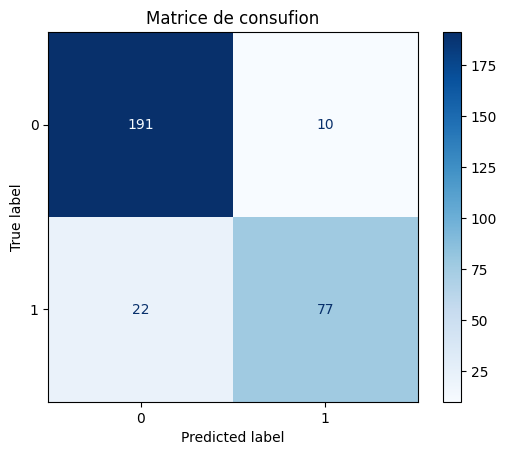

In [96]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm).plot(cmap="Blues")
plt.title("Matrice de consufion")
plt.show()

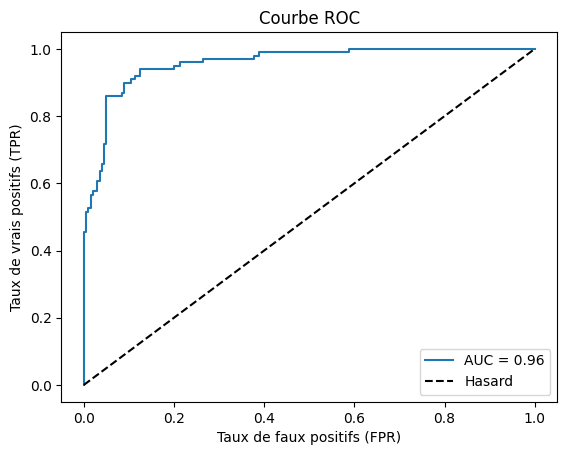

In [97]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0, 1], [0, 1], "k--", label="Hasard")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.title("Courbe ROC")
plt.legend()
plt.show()